# 01 · Preprocessing — Zhang 2021 Renal Cell Carcinoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap**, integrate patients (Harmony on `sample`), embed, remove detached islands, and
split the manifold into its transcriptional compartments. Zhang et al. profiled kidney
tumours by 10x; the malignant compartment here mixes **clear-cell RCC** and a smaller
**chromophobe RCC** contribution. Whether the gastrulation / somitogenesis / neural-crest
developmental axis is confined to one lobe (Kürten 2021) or spans the whole manifold
(Bischoff / Sun / Lee 2020) is **derived in 02 from the signature geography**, not assumed
here, so all compartments are carried forward. Every tunable choice is *derived from this
dataset*, not inherited from the Puram anchor. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Zhang2021_Kidney-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Kidney'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

raw_name = 'Data_Zhang2021_Kidney'                      # raw folder ('-1' is an output suffix only)
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Zhang2021_Kidney-1 | category: Kidney


### Load malignant compartment
The loader auto-detects normalization from the matrix filename (`Exp_data_UMIcounts.mtx`
→ UMI counts → `normalize_total` + `log1p`) and sets `celltype` from the publication's
`cell_type` column. Zhang's malignant cells are already labelled `Malignant`; we take
those (the publication's malignancy calls, per protocol) and analyse them only.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas load:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('malignant disease mix:', adata.obs['disease'].value_counts().to_dict())
print('cell_cycle_phase:', adata.obs['cell_cycle_phase'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Zhang2021_Kidney
Done.
full atlas load: (29474, 33694)
malignant: (11410, 33694) | samples: 8
malignant disease mix: {'Clear_Cell_RCC': 9139, 'Chromophobe_RCC': 2271}
cell_cycle_phase: {'Not cycling': 10757, 'G1/S': 242, 'G2/M': 92, 'Intermediate': 25}
expression: X max 8.20 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span an order of magnitude. Rather than a round-number cut
(the anchor's `>=100` is *illustrative*, not a default), we find the largest
**multiplicative** cliff in the sorted counts and cut at its geometric mean — the natural
separatrix between tumour-bearing samples and spillover. This is derived from *this*
dataset's count distribution (C1/C2).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.tolist())
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [3443, 2271, 1409, 1209, 1184, 992, 710, 192]
largest multiplicative gap: 710 -> 192 (ratio 3.70)
derived threshold (geometric mean across the gap) = 369
kept 7/8 samples -> 11218 cells


### Overdispersion, PCA, Harmony integration, embedding
`n_pcs=20` and `spread=1.3` follow the 10x precedents at this cell scale (Kürten / Sun /
Lee / Zhou, ~2k-33k cells; the anchor's 40 PCs was tuned to SmartSeq2). `theta` is
selected by a same-sample-neighbour-fraction + iLISI sweep (lower same-sample fraction /
higher iLISI = better mixing): RCC malignant cells carry strong patient-specific CNVs, so
integration is pushed to the strongest theta at which mixing plateaus.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio (top 10):', np.round(vr[:10], 4).tolist())
print('elbow: variance ratio flattens below PC ~10-20; n_pcs=20 spans the informative range')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1363 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1363
PCA variance ratio (top 10): [0.211, 0.082, 0.0567, 0.0344, 0.0232, 0.0217, 0.0182, 0.0125, 0.01, 0.009]
elbow: variance ratio flattens below PC ~10-20; n_pcs=20 spans the informative range


In [6]:
# theta sweep: same-sample neighbour fraction (lower=better) + per-neighbourhood iLISI (higher=better)
from sklearn.neighbors import NearestNeighbors
NPC = 20
def same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
base = same_sample_frac(adata.obsm['X_pca'][:,:NPC])
il_pre = float(np.median(ilisi(adata.obsm['X_pca'][:,:NPC], adata.obs['sample'].values)))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    ss = same_sample_frac(adata.obsm['X_pca_harmony'][:,:NPC])
    il = float(np.median(ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values)))
    sweep[th] = (ss, il)
print(f'{nsamp} samples | pre-Harmony: same-sample frac {base:.3f}, iLISI {il_pre:.2f}')
for th in [2,5,10]:
    print(f'  theta={th}: same-sample frac {sweep[th][0]:.3f}, iLISI {sweep[th][1]:.2f}')
# DERIVE theta from the sweep (C2: computed, not asserted). Rule: mixing (iLISI) rises
# monotonically with theta; take the strongest theta only if the marginal gain has
# plateaued (last step's gain <= half the first step's gain) -> diminishing returns,
# so no collapse risk from over-integrating. Otherwise take the argmax iLISI.
thetas = [2, 5, 10]
il_seq = [sweep[t][1] for t in thetas]
gains = [il_seq[i] - il_seq[i-1] for i in range(1, len(il_seq))]
plateaued = gains[-1] <= 0.5 * gains[0]
theta = thetas[-1] if plateaued else thetas[int(np.argmax(il_seq))]
print(f'iLISI gains across theta steps: {[round(g,2) for g in gains]}; '
      f'plateaued (last <= 0.5*first)? {plateaued}')
print(f'selected theta = {theta} (derived: strongest integration once per-neighbourhood mixing plateaus)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

2026-08-06 00:41:37,485 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-06 00:41:38,815 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-06 00:41:38,879 - harmonypy - INFO - Iteration 1 of 30
2026-08-06 00:41:41,181 - harmonypy - INFO - Iteration 2 of 30
2026-08-06 00:41:43,479 - harmonypy - INFO - Iteration 3 of 30
2026-08-06 00:41:45,759 - harmonypy - INFO - Iteration 4 of 30
2026-08-06 00:41:48,051 - harmonypy - INFO - Converged after 4 iterations
2026-08-06 00:41:48,781 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-06 00:41:49,993 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-06 00:41:50,035 - harmonypy - INFO - Iteration 1 of 30
2026-08-06 00:41:52,337 - harmonypy - INFO - Iteration 2 of 30
2026-08-06 00:41:54,588 - harmonypy - INFO - Iteration 3 of 30
2026-08-06 00:41:56,837 - harmonypy - INFO - Iteration 4 of 30
2026-08-06 00:41:59,076 - harmonypy - INFO - Iteration 5 of 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and drop any
cell outside the main connected component — stripping physically detached specks while
keeping the continuous manifold intact.

In [7]:
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape)

removed 0 cells in 0 detached islands
after island removal: (11218, 23065)


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. We label them *by biology*:
the compartment with the **lower cycling fraction** is the **Embryonic** candidate; the rest
are **Cycling/Metabolic**. `cell_cycle_phase` comes from the publication's phase calls.
Here cycling is globally low (~3%), so the split is transcriptional-state, not a cell-cycle
partition; whether the trajectory is scoped to one lobe or spans all is decided in 02 from
the signature geography, not assumed here.

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('disease per lobe:')
print(pd.crosstab(adata.obs['lobe'], adata.obs['disease']).to_string())
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling/Metabolic')
           for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 9545, '1': 1673}
cycling fraction per lobe: {'0': 0.036, '1': 0.009}
disease per lobe:
disease  Chromophobe_RCC  Clear_Cell_RCC
lobe                                    
0                   1927            7618
1                    344            1329
compartments: {'Cycling/Metabolic': 9545, 'Embryonic': 1673}


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all trajectory panels
are shown after a single **rigid rotation** to the house horizontal layout
(distance-preserving — *not* a re-embedding). The orientation is derived **once here**,
stored as `X_umap_lin`, and re-used unchanged by 02/03/04 so every deliverable UMAP shares
one orientation (binding). Two ingredients, both available pre-trajectory: (i) the rotation
angle = the manifold's **axis of maximal variance**; (ii) the sign = put the
**developmental origin (posterior-somitogenesis-high) pole on the left**, so pseudotime will
run left->right once fit in 02. We score pSom here only to fix that sign; 02 verifies the
layout against pseudotime (corr must be strongly positive).

In [9]:
# quick pSom score (union control pool) — used ONLY to orient the sign here
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
g_ps = feat['GSE229103'].loc[feat['GSE229103'].isin(adata.var_names)]
sc.tl.score_genes(adata, gene_list=g_ps, score_name='_pSom_orient', ctrl_as_ref=False,
                  gene_pool=g_ref, random_state=1234)
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)],
               [np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = adata.obs['_pSom_orient'].values                      # pSom-high (origin) pole -> left
if np.average(xyr[:,0], weights=(w - w.min() + 1e-9)) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
del adata.obs['_pSom_orient']
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'somitogenesis-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.23
house orientation: rigid rotation -100.1deg (distances preserved), somitogenesis-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made
on the regenerated embedding itself plus a per-neighbourhood metric (iLISI across the theta
sweep), not a scalar alone; the deliverable `samples.pdf` follows and shows the intermixing
directly.

In [10]:
il_post = sweep[theta][1]
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsamp} samples')
print(f'{nsamp} samples share one continuous manifold (one connected component after island removal);')
print('both compartments contain multiple samples; clear-cell and chromophobe RCC intermix')
print('rather than forming per-disease islands.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 3.17 of 7 samples
7 samples share one continuous manifold (one connected component after island removal);
both compartments contain multiple samples; clear-cell and chromophobe RCC intermix
rather than forming per-disease islands.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


### Save processed data

In [11]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (11218, 23065)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, shown on the house orientation
(`X_umap_lin`). Colour = sample: intermixing across the strip is the Gate-1 evidence.

saved samples.pdf | cells: 11218


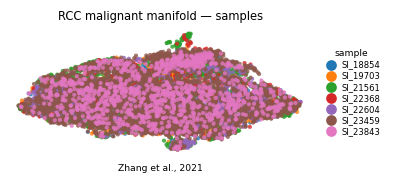

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('RCC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Zhang et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])